# Student Dropout & Academic Success - Classification Project
## Notebook 1: Problem Definition -> Data -> EDA -> Cleaning -> Feature Engineering -> Splitting

**How to read this notebook.** Every step has a short *"What / Why"* explanation written for someone new to machine learning (ML). If a word is unfamiliar, look for it in the **Glossary** at the bottom.

**ML process steps covered here**:
1. Problem Definition
2. Data Collection
3. Data Exploration and Preparation (EDA, cleaning, feature engineering, splitting)

---
# Step 1 - Problem Definition

### The real-world problem
Universities lose a large number of students who start a degree but never finish it. If a university can **spot at-risk students early**, advisors can offer help (tutoring, financial aid, counselling) before it is too late.

### The ML question
> Given what we know about a student (background, finances, and first-year performance), can we predict whether they will **Dropout**, remain **Enrolled**, or **Graduate**?

### What type of ML problem is this?
* We have the **correct answer** (the label) for every past student, so this is **supervised learning**.
* The answer is one of **3 categories**, not a number, so it is **classification** (specifically *multi-class* classification).
  * If the answer were a number (e.g. a building's energy use), it would be *regression* - that is our second project.

### Success criteria (how we will judge the model)
| Metric | Plain-English meaning | Why it matters here |
|---|---|---|
| **Accuracy** | % of students predicted correctly | Easy to understand, but can be *misleading* when classes are unbalanced (see EDA). |
| **Recall of Dropout** | Of all students who *really* dropped out, what % did we catch? | Missing an at-risk student is the costly mistake, so this is our **key metric**. |
| **Precision** | When we say "Dropout", how often are we right? | Too many false alarms waste advisors' time. |
| **Macro F1-score** | One score that balances precision and recall, averaged equally over all 3 classes | Our **main overall score**, because it does not let the biggest class hide poor results on small classes. |
| **ROC-AUC (one-vs-rest)** | How well the model *ranks* students from low risk to high risk (0.5 = guessing, 1.0 = perfect) | Shows quality independent of any threshold. |

**Targets we set before looking at results:** macro-F1 of at least **0.70**, and Dropout recall of at least **0.75**. Setting goals *first* prevents us from fooling ourselves later.

---
# Step 2 - Data Collection

We use the public **"Predict Students' Dropout and Academic Success"** dataset from the UCI Machine Learning Repository (ID 697, licence CC BY 4.0).
Source: Realinho, Vieira Martins, Machado & Baptista (2021), DOI 10.24432/C5MC89.

It was collected at a Portuguese higher-education institution and covers many degrees (nursing, management, design, agronomy, ...). Each **row = one student**; each **column = one fact** about that student.

The file `data/students_dropout.csv` was downloaded earlier by `00_download_data.py`, so this notebook always works from exactly the same data.

In [1]:
import re, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

SEED = 42                       # fixed "random seed" so results are repeatable
DATA, FIG = Path("data"), Path("figures")
FIG.mkdir(exist_ok=True)

# One fixed colour per class, used in every chart so the story stays consistent
PALETTE = {"Dropout": "#d1495b", "Enrolled": "#edae49", "Graduate": "#00798c"}
CLASSES = ["Dropout", "Enrolled", "Graduate"]

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

df = pd.read_csv(DATA / "students_dropout.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (4424, 37)


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


**What we see:** 4,424 students and 37 columns (36 inputs + 1 target called `Target`).
In ML the input columns are called **features** (often written **X**) and the thing we predict is called the **target** or **label** (written **y**).

---
# Step 3 - Data Exploration and Preparation

## 3.1 Exploratory Data Analysis (EDA)
**What:** looking at the data with tables and charts *before* building anything.
**Why:** a model is only as good as the data it learns from. EDA reveals problems (missing values, strange numbers), shows which facts seem related to dropping out, and guides every later decision.

### 3.1.1 Basic health check

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

In [3]:
print("Missing values in total :", int(df.isna().sum().sum()))
print("Duplicate rows          :", int(df.duplicated().sum()))

Missing values in total : 0
Duplicate rows          : 0


**Reading the result:** no missing values and no duplicate rows. Real-world data is rarely this tidy (this dataset was already pre-processed by its authors), but we still *check* - never assume.

### 3.1.2 Understanding the columns - an important trap
Look at the `dtypes` above: most columns are integers (`int64`). **But integers are not always numbers!** Many of them are *codes* for a category:

* `Course = 9500` is a degree programme ID, not a quantity. Course 9500 is not "bigger" than course 33.
* `Marital Status`, `Application mode`, `Mother's occupation`, ... are the same: codes standing for labels.

If we feed codes to a model as if they were quantities, it will wrongly think `9500 > 33` means something. So we will separate columns into three groups later:

| Group | Example | How we will treat it |
|---|---|---|
| **Numeric** (real quantities) | `Admission grade`, `Age at enrollment` | Scale them |
| **Binary** (yes/no stored as 1/0) | `Gender`, `Debtor`, `Scholarship holder` | Keep as they are |
| **Nominal categorical** (codes for labels) | `Course`, `Marital Status` | One-hot encode |

### 3.1.3 The target: how are the 3 classes distributed?

          students  percent
Target                     
Dropout       1421     32.1
Enrolled       794     17.9
Graduate      2209     49.9


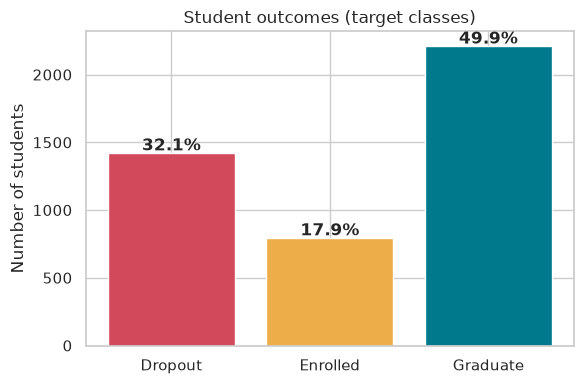

In [4]:
counts = df["Target"].value_counts().reindex(CLASSES)
pct = (counts / counts.sum() * 100).round(1)
print(pd.DataFrame({"students": counts, "percent": pct}))

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(CLASSES, counts.values, color=[PALETTE[c] for c in CLASSES])
for b, p in zip(bars, pct):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 20, f"{p}%", ha="center", fontweight="bold")
ax.set_title("Student outcomes (target classes)")
ax.set_ylabel("Number of students")
save("01_target_distribution")
plt.show()

**Key finding - class imbalance.** About half the students Graduate, about a third Drop out, and only ~18% are still Enrolled.

**Why this matters:** imagine a lazy model that *always* says "Graduate". It would be right ~50% of the time (accuracy 50%) while catching **zero** dropouts - useless for our purpose! This is why accuracy alone is not enough and why we chose **macro-F1** and **Dropout recall** as success metrics.
We will also use **stratified** splitting (keeps the same class percentages in every subset) and later try **class weights** (telling the model that mistakes on small classes cost more).

### 3.1.4 Numeric features: shape of the data
**Histograms** show how values are spread out. Skewed or odd shapes hint at outliers or special groups.

In [6]:
key_numeric = ["Admission grade", "Previous qualification (grade)", "Age at enrollment",
               "Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)",
               "Curricular units 1st sem (approved)"]

df[key_numeric].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Admission grade,4424.0,126.98,14.48,95.0,117.90,126.10,134.80,190.00
Previous qualification (grade),4424.0,132.61,13.19,95.0,125.00,133.10,140.00,190.00
Age at enrollment,4424.0,23.27,7.59,17.0,19.00,20.00,25.00,70.00
Curricular units 1st sem (grade),4424.0,10.64,4.84,0.0,11.00,12.29,13.40,18.88
Curricular units 2nd sem (grade),4424.0,10.23,5.21,0.0,10.75,12.20,13.33,18.57
Curricular units 1st sem (approved),4424.0,4.71,3.09,0.0,3.00,5.00,6.00,26.00


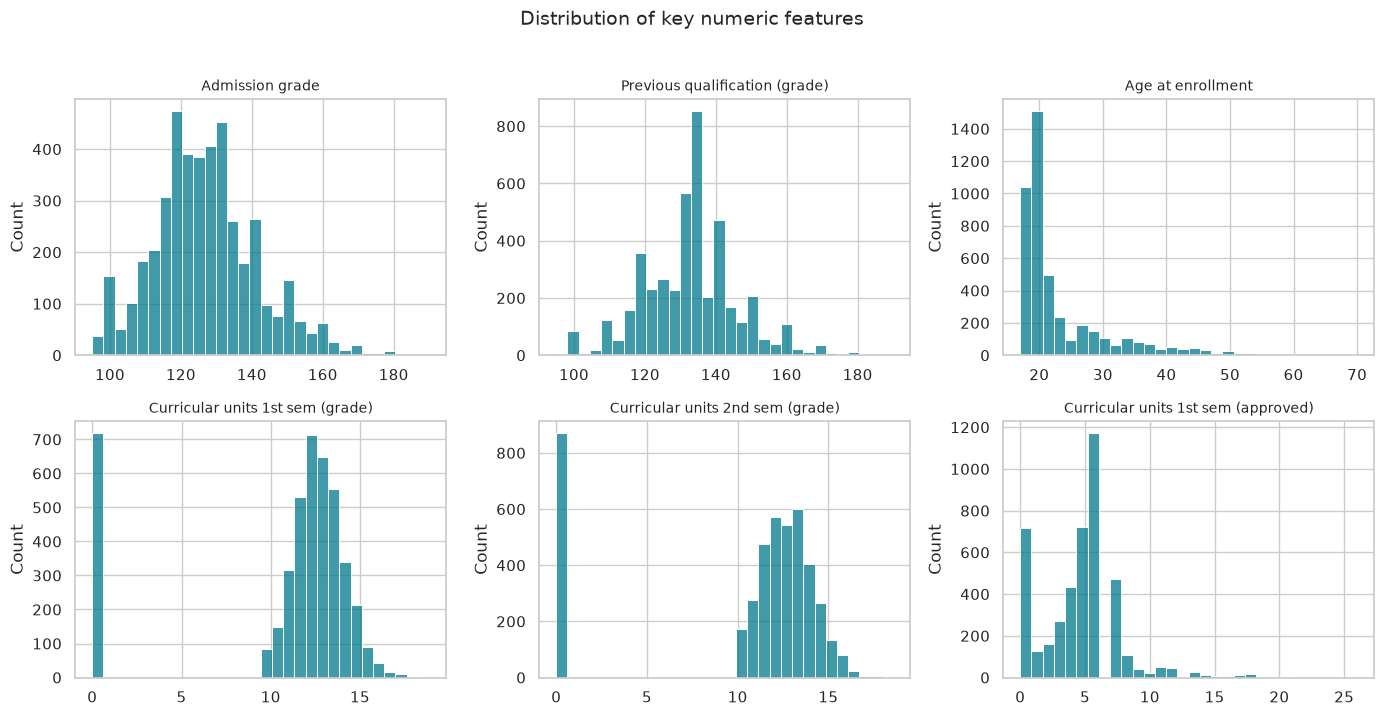

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), key_numeric):
    sns.histplot(df[col], bins=30, ax=ax, color="#00798c")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
plt.suptitle("Distribution of key numeric features", fontsize=14, y=1.02)
save("02_numeric_histograms")
plt.show()

**What to notice**
* **Age at enrollment** is *right-skewed*: most students are ~18-20, but there is a long tail of mature students (up to 70). These are real people, not errors.
* **Semester grades** have a spike at **0** (718 students in the 1st semester, 870 in the 2nd). A grade of 0 means the student has no graded passing result that semester. In the data, **84% of students with a 2nd-semester grade of 0 dropped out**, so this is a strong early-warning signal, not noise.

### 3.1.5 Which features separate the classes?
A **box plot** shows the middle 50% of values as a box, the median as the line inside, and individual dots as unusual values. If boxes for Dropout / Enrolled / Graduate sit at different heights, that feature helps tell them apart.

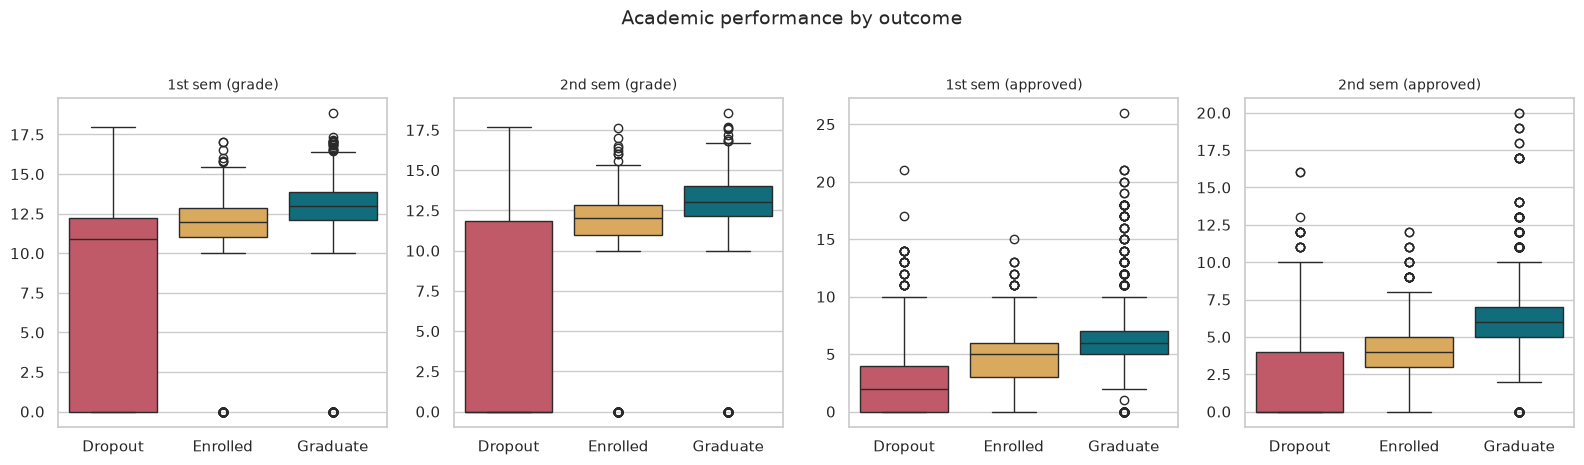

In [8]:
perf_cols = ["Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)",
             "Curricular units 1st sem (approved)", "Curricular units 2nd sem (approved)"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, col in zip(axes, perf_cols):
    sns.boxplot(data=df, x="Target", y=col, order=CLASSES, palette=PALETTE, ax=ax)
    ax.set_title(col.replace("Curricular units ", ""), fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("Academic performance by outcome", fontsize=14, y=1.03)
save("03_performance_by_target")
plt.show()

**Finding:** Dropouts have much lower grades and far fewer approved course units than Graduates, especially in the 2nd semester. First-year academic performance is a very strong signal.

> **Important caution (data leakage / timing).** 2nd-semester results only exist *late* in the first year. If the university wants to warn students *early*, it would only have background info and 1st-semester data. We will test the model both **with** and **without** 2nd-semester features in the next notebook, and be honest about the difference.

### 3.1.6 Yes/No features vs. outcome
For each yes/no feature we compare the **dropout rate** between the two groups.

In [9]:
binary_raw = ["Tuition fees up to date", "Scholarship holder", "Debtor", "Gender", "Displaced",
              "International", "Educational special needs", "Daytime/evening attendance"]
labels = {"Gender": ("Female", "Male"), "Daytime/evening attendance": ("Evening", "Daytime")}

rows = []
for c in binary_raw:
    for v in (0, 1):
        sub = df[df[c] == v]
        name = labels.get(c, ("No", "Yes"))[v]
        rows.append({"feature": c, "group": name, "n": len(sub),
                     "dropout_rate_%": round((sub["Target"] == "Dropout").mean() * 100, 1)})
rate = pd.DataFrame(rows)
rate

,feature,group,n,dropout_rate_%
0,Tuition fees up to date,No,528,86.6
1,Tuition fees up to date,Yes,3896,24.7
2,Scholarship holder,No,3325,38.7
3,Scholarship holder,Yes,1099,12.2
4,Debtor,No,3921,28.3
5,Debtor,Yes,503,62.0
6,Gender,Female,2868,25.1
7,Gender,Male,1556,45.1
8,Displaced,No,1998,37.6
9,Displaced,Yes,2426,27.6


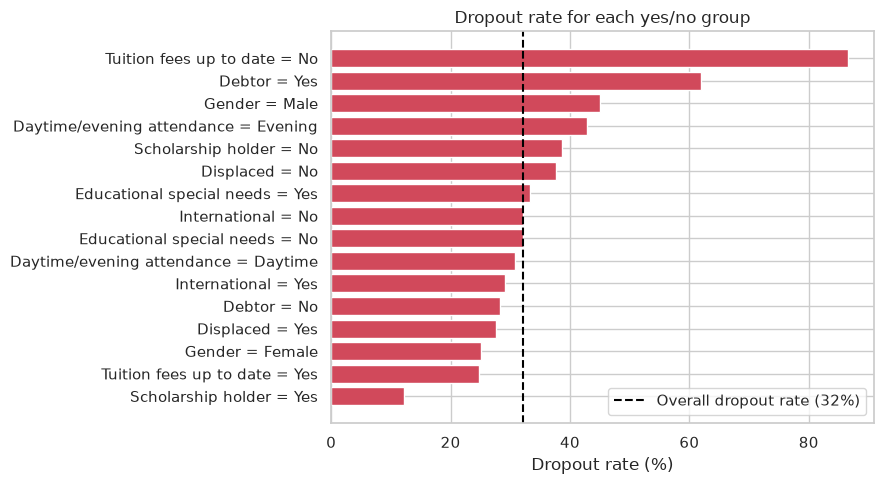

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
plot = rate.copy()
plot["label"] = plot["feature"] + " = " + plot["group"]
plot = plot.sort_values("dropout_rate_%")
ax.barh(plot["label"], plot["dropout_rate_%"], color="#d1495b")
ax.axvline((df["Target"] == "Dropout").mean() * 100, color="black", ls="--", label="Overall dropout rate (32%)")
ax.set_xlabel("Dropout rate (%)"); ax.legend()
ax.set_title("Dropout rate for each yes/no group")
save("04_binary_dropout_rates")
plt.show()

**Findings:** students whose **tuition fees are not up to date** drop out at a very high rate; **scholarship holders** drop out far less; **debtors** and **men** drop out more. So finances and support matter, not only grades.

### 3.1.7 Does the degree programme matter?

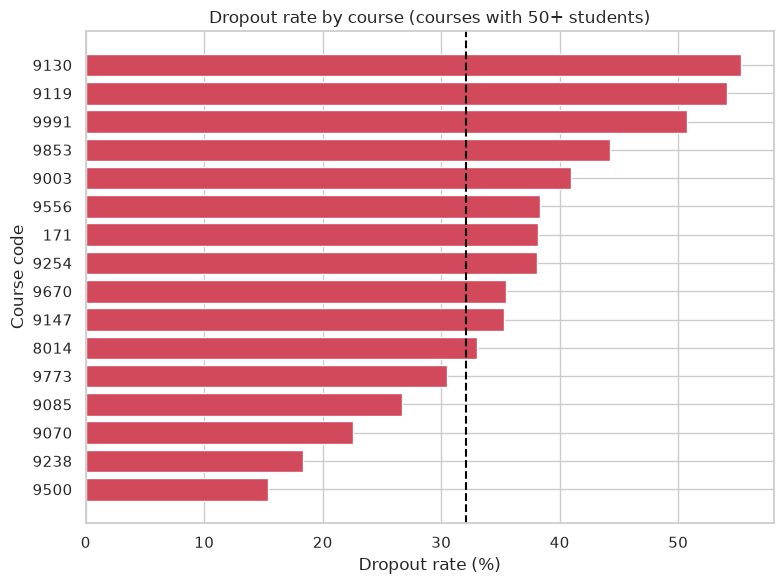

In [11]:
course = (df.groupby("Course")["Target"]
            .agg(students="size", dropout_rate=lambda s: (s == "Dropout").mean() * 100)
            .query("students >= 50").sort_values("dropout_rate"))

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(course.index.astype(str), course["dropout_rate"], color="#d1495b")
ax.axvline((df["Target"] == "Dropout").mean() * 100, color="black", ls="--")
ax.set_xlabel("Dropout rate (%)"); ax.set_ylabel("Course code")
ax.set_title("Dropout rate by course (courses with 50+ students)")
save("05_dropout_by_course")
plt.show()

**Finding:** dropout rate varies a lot between degree programmes (from about 15% for the best course to about 55% for the worst), so `Course` is informative - but remember it is a **code**, which is why we will one-hot encode it.

### 3.1.8 Correlation with dropping out
**Correlation** is a number from -1 to +1 describing how two columns move together (+1 = rise together, -1 = one rises as the other falls, 0 = unrelated). Here we measure each feature's correlation with "this student dropped out" (1 = yes, 0 = no).
Correlation only captures *straight-line* relationships and does **not** prove cause - it is a quick screening tool.

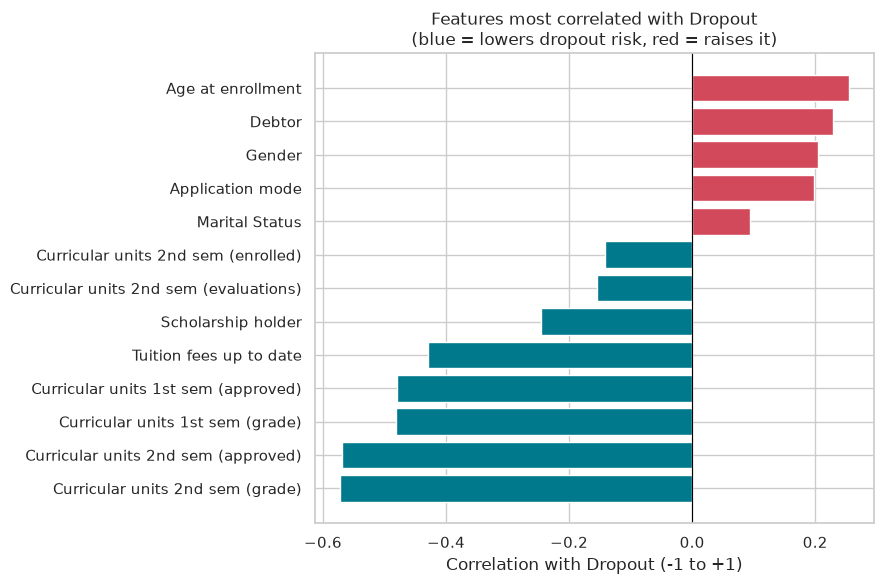

In [12]:
is_dropout = (df["Target"] == "Dropout").astype(int)
corr = df.drop(columns="Target").corrwith(is_dropout).sort_values()
top = pd.concat([corr.head(8), corr.tail(5)])

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color=["#00798c" if v < 0 else "#d1495b" for v in top.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Features most correlated with Dropout\n(blue = lowers dropout risk, red = raises it)")
ax.set_xlabel("Correlation with Dropout (-1 to +1)")
save("06_correlation_with_dropout")
plt.show()

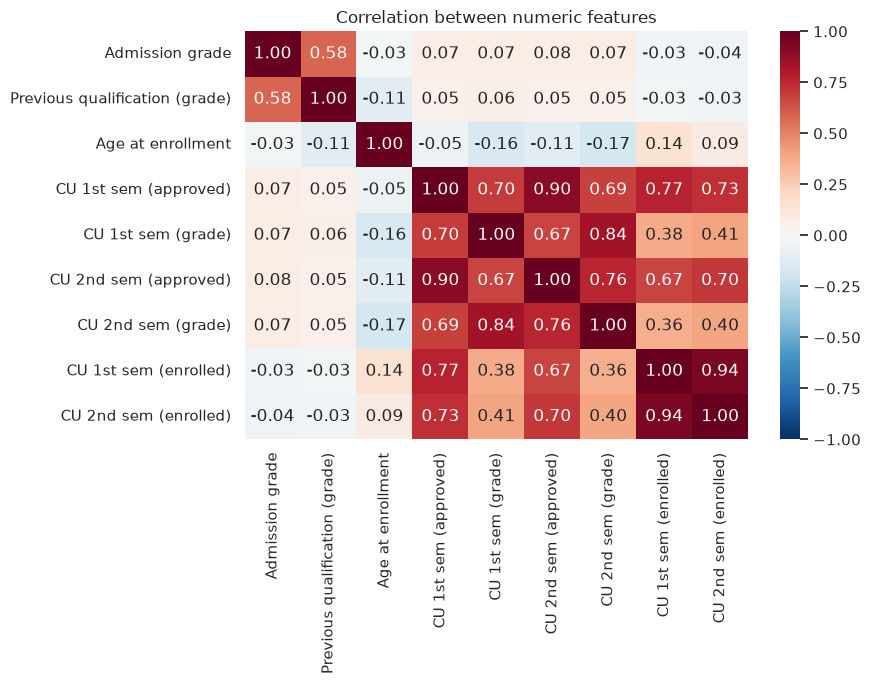

In [13]:
num_for_heat = ["Admission grade", "Previous qualification (grade)", "Age at enrollment",
                "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
                "Curricular units 2nd sem (approved)", "Curricular units 2nd sem (grade)",
                "Curricular units 1st sem (enrolled)", "Curricular units 2nd sem (enrolled)"]
short = [c.replace("Curricular units ", "CU ") for c in num_for_heat]
cm = df[num_for_heat].corr()
cm.index = cm.columns = short

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between numeric features")
save("07_feature_correlation_heatmap")
plt.show()

**Findings**
* The strongest links with dropout are *2nd- and 1st-semester grades and approved units* (about -0.57 and -0.48: more passed units -> less dropout), then *tuition fees up to date* (-0.43) and *scholarship holder* (-0.25). On the risk-raising side, *age at enrollment* (+0.25) and being a *debtor*, *male* or having a certain *application mode* (about +0.20 to +0.23).
* The heatmap shows **1st-sem and 2nd-sem features are strongly correlated with each other** (e.g. 1st-sem approved units vs 2nd-sem approved units: 0.90). This is called **multicollinearity**: two columns carrying almost the same information. Tree-based models handle it fine, but it can confuse plain linear models such as Logistic Regression - one reason we will compare several algorithms.

---
## 3.2 Data Cleaning
**What:** fixing problems in the raw data.  **Why:** wrong or messy data leads to wrong conclusions ("garbage in, garbage out").

### 3.2.1 Missing values & duplicates
Both were checked above: **none found**, so nothing to remove or fill in. (If there had been missing values we would *impute* - fill with the median/most-frequent value - **only using training data statistics**.)

### 3.2.2 Inconsistent names
Column names contain spaces, brackets and apostrophes, and one is misspelled (`Nacionality`). We standardise to clean `snake_case` names so they are safe to use in code.

In [15]:
def clean_name(col):
    col = col.lower().replace("'", "")
    return re.sub(r"[^0-9a-z]+", "_", col).strip("_")

df = df.rename(columns=clean_name).rename(columns={"nacionality": "nationality"})
print(list(df.columns))

['marital_status', 'application_mode', 'application_order', 'course', 'daytime_evening_attendance', 'previous_qualification', 'previous_qualification_grade', 'nationality', 'mothers_qualification', 'fathers_qualification', 'mothers_occupation', 'fathers_occupation', 'admission_grade', 'displaced', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'age_at_enrollment', 'international', 'curricular_units_1st_sem_credited', 'curricular_units_1st_sem_enrolled', 'curricular_units_1st_sem_evaluations', 'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade', 'curricular_units_1st_sem_without_evaluations', 'curricular_units_2nd_sem_credited', 'curricular_units_2nd_sem_enrolled', 'curricular_units_2nd_sem_evaluations', 'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade', 'curricular_units_2nd_sem_without_evaluations', 'unemployment_rate', 'inflation_rate', 'gdp', 'target']


### 3.2.3 Logical consistency checks
We test rules that *must* be true in sensible data.

In [16]:
checks = {
    "1st sem: approved units > enrolled units":
        int((df["curricular_units_1st_sem_approved"] > df["curricular_units_1st_sem_enrolled"]).sum()),
    "2nd sem: approved units > enrolled units":
        int((df["curricular_units_2nd_sem_approved"] > df["curricular_units_2nd_sem_enrolled"]).sum()),
    "1st sem: grade is 0 but units approved":
        int(((df["curricular_units_1st_sem_grade"] == 0) & (df["curricular_units_1st_sem_approved"] > 0)).sum()),
    "Age below 17 at enrollment":
        int((df["age_at_enrollment"] < 17).sum()),
    "Admission grade outside 0-200":
        int((~df["admission_grade"].between(0, 200)).sum()),
}
pd.Series(checks, name="rows violating rule").to_frame()

,rows violating rule
1st sem: approved units > enrolled units,0
2nd sem: approved units > enrolled units,0
1st sem: grade is 0 but units approved,0
Age below 17 at enrollment,0
Admission grade outside 0-200,0


**Reading the result.** Every rule passes with **0 violations**: nobody has more approved than enrolled units, no grade is out of range, and no student is younger than 17. The data is logically consistent, so no rows need to be removed or corrected.

### 3.2.4 Outliers
An **outlier** is a value far from the rest. A standard rule (the *IQR rule*) flags values more than 1.5 x IQR beyond the middle 50% of the data. **Flagging is not the same as deleting** - first we ask *is it an error or a real value?*

In [17]:
cont = ["previous_qualification_grade", "admission_grade", "age_at_enrollment",
        "curricular_units_1st_sem_grade", "curricular_units_2nd_sem_grade",
        "unemployment_rate", "inflation_rate", "gdp"]
out = []
for c in cont:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    out.append({"feature": c, "outliers": n, "percent": round(n / len(df) * 100, 1)})
pd.DataFrame(out)

,feature,outliers,percent
0,previous_qualification_grade,179,4.0
1,admission_grade,86,1.9
2,age_at_enrollment,441,10.0
3,curricular_units_1st_sem_grade,726,16.4
4,curricular_units_2nd_sem_grade,877,19.8
5,unemployment_rate,0,0.0
6,inflation_rate,0,0.0
7,gdp,0,0.0


**Decision: keep the outliers.** They are genuine students (older learners, and the many students with a semester grade of 0, which is where most of the grade "outliers" come from), not typing errors, and *they carry the dropout signal*. Deleting them would throw away exactly the at-risk cases we want to find. Tree-based models are naturally insensitive to extreme values, and for models that are sensitive, **scaling** (below) reduces the impact.

---
## 3.3 Feature Engineering
**What:** creating new, more useful columns from existing ones, and converting columns into a form models can use.
**Why:** a model sees only the numbers we give it. A smart new column can expose a pattern that was hidden.

### 3.3.1 New features
Raw counts like "approved = 5" mean different things for a student who enrolled in 6 units vs. 5 units. **Ratios** capture this:

In [18]:
def safe_ratio(num, den):
    """num/den, but 0 when den is 0 (avoids division by zero)."""
    return np.where(den > 0, num / den.replace(0, np.nan), 0.0)

df["sem1_approval_rate"] = safe_ratio(df["curricular_units_1st_sem_approved"], df["curricular_units_1st_sem_enrolled"])
df["sem2_approval_rate"] = safe_ratio(df["curricular_units_2nd_sem_approved"], df["curricular_units_2nd_sem_enrolled"])
df["total_units_approved"] = df["curricular_units_1st_sem_approved"] + df["curricular_units_2nd_sem_approved"]
df["total_units_enrolled"] = df["curricular_units_1st_sem_enrolled"] + df["curricular_units_2nd_sem_enrolled"]
df["overall_approval_rate"] = safe_ratio(df["total_units_approved"], df["total_units_enrolled"])
df["grade_change"] = df["curricular_units_2nd_sem_grade"] - df["curricular_units_1st_sem_grade"]

new_feats = ["sem1_approval_rate", "sem2_approval_rate", "total_units_approved",
             "total_units_enrolled", "overall_approval_rate", "grade_change"]
df[new_feats].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
sem1_approval_rate,4424.0,0.70,0.37,0.00,0.5,0.83,1.00,1.0
sem2_approval_rate,4424.0,0.66,0.38,0.00,0.4,0.83,1.00,1.0
total_units_approved,4424.0,9.14,5.96,0.00,5.0,10.00,12.00,43.0
total_units_enrolled,4424.0,12.50,4.61,0.00,10.0,12.00,14.00,46.0
overall_approval_rate,4424.0,0.68,0.36,0.00,0.5,0.83,1.00,1.0
grade_change,4424.0,-0.41,2.89,-16.14,-0.6,0.00,0.45,16.0


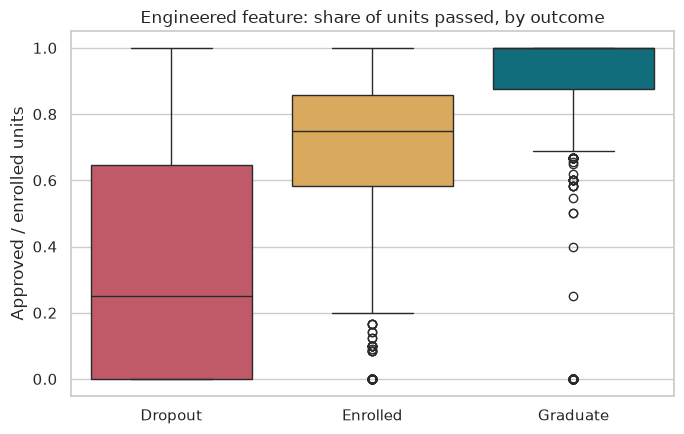

In [17]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=df, x="target", y="overall_approval_rate", order=CLASSES, palette=PALETTE, ax=ax)
ax.set_title("Engineered feature: share of units passed, by outcome")
ax.set_xlabel(""); ax.set_ylabel("Approved / enrolled units")
save("08_engineered_feature")
plt.show()

The new `overall_approval_rate` separates the classes clearly (Graduates pass nearly everything, Dropouts pass little), so it was worth creating.

### 3.3.2 Grouping columns by type
As explained in 3.1.2, we tell the pipeline which columns are *numeric*, *binary* and *nominal categorical*.

In [19]:
TARGET = "target"
binary_cols = ["daytime_evening_attendance", "displaced", "educational_special_needs", "debtor",
               "tuition_fees_up_to_date", "gender", "scholarship_holder", "international"]
nominal_cols = ["marital_status", "application_mode", "course", "previous_qualification", "nationality",
                "mothers_qualification", "fathers_qualification", "mothers_occupation", "fathers_occupation"]
numeric_cols = [c for c in df.columns if c not in binary_cols + nominal_cols + [TARGET]]

print(f"numeric ({len(numeric_cols)}):", numeric_cols, "\n")
print(f"binary ({len(binary_cols)}):", binary_cols, "\n")
print(f"nominal ({len(nominal_cols)}):", nominal_cols)
print("\nTotal input features:", len(numeric_cols) + len(binary_cols) + len(nominal_cols),
      "(36 original + 6 engineered)")

numeric (25): ['application_order', 'previous_qualification_grade', 'admission_grade', 'age_at_enrollment', 'curricular_units_1st_sem_credited', 'curricular_units_1st_sem_enrolled', 'curricular_units_1st_sem_evaluations', 'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade', 'curricular_units_1st_sem_without_evaluations', 'curricular_units_2nd_sem_credited', 'curricular_units_2nd_sem_enrolled', 'curricular_units_2nd_sem_evaluations', 'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade', 'curricular_units_2nd_sem_without_evaluations', 'unemployment_rate', 'inflation_rate', 'gdp', 'sem1_approval_rate', 'sem2_approval_rate', 'total_units_approved', 'total_units_enrolled', 'overall_approval_rate', 'grade_change'] 

binary (8): ['daytime_evening_attendance', 'displaced', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'international'] 

nominal (9): ['marital_status', 'application_mode', 'course', 'previous_

### 3.3.3 Encoding the target
Algorithms work with numbers, so the class names become integers (**label encoding**): `Dropout = 0, Enrolled = 1, Graduate = 2`. This is just a name tag; the order carries no meaning.

### 3.3.4 Encoding categorical features (one-hot encoding) and scaling numeric features
* **One-hot encoding:** replace a code column by one yes/no column per category. `course` with 17 programmes becomes 17 columns, and exactly one of them is 1 for each student. This removes the false idea that code 9500 is "bigger" than code 33.
* **Scaling (standardisation):** rewrite each numeric column as *"how many standard deviations from average"*, i.e. mean 0 and spread 1. Without it, a feature measured in hundreds (admission grade ~ 126) would drown out one measured in fractions (inflation ~ 1.4) for distance- and gradient-based models (Logistic Regression, SVM, neural networks). Trees do not need it, but scaling does them no harm.

> **Golden rule - prevent data leakage:** the encoder/scaler must **learn its numbers (means, categories) from the training data only** and then just *apply* them to validation and test data. If it peeked at the test data, our final score would be unrealistically good. We therefore **split first, preprocess second**.

---
## 3.4 Data Splitting
**What:** dividing the data into three separate parts.

| Part | Share | Purpose (school analogy) |
|---|---|---|
| **Training set** | 70% | Practice exercises the model learns from |
| **Validation set** | 15% | Mock exam - used to compare models and tune settings |
| **Test set** | 15% | The real final exam - touched **once**, at the very end |

**Why three parts?** If we judged the model on the same data it studied, it could simply memorise the answers (**overfitting**) and look perfect while failing on new students. The test set simulates "new students the model has never seen".

`stratify=y` keeps the 50/32/18% class mix identical in all three parts, and `random_state=42` makes the split repeatable.

In [20]:
le = LabelEncoder().fit(CLASSES)           # Dropout=0, Enrolled=1, Graduate=2
y = le.transform(df[TARGET])
X = df.drop(columns=TARGET)
print("Class mapping:", {str(c): int(i) for c, i in zip(le.classes_, le.transform(le.classes_))})

# 70% train, 30% temporary; then split the temporary part half/half -> 15% val, 15% test
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

summary = pd.DataFrame({
    "rows": [len(y_train), len(y_val), len(y_test)],
    **{c: [round((s == i).mean() * 100, 1) for s in (y_train, y_val, y_test)] for i, c in enumerate(le.classes_)}
}, index=["train", "validation", "test"])
summary.columns = ["rows"] + [f"% {c}" for c in le.classes_]
summary

Class mapping: {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}


,rows,% Dropout,% Enrolled,% Graduate
train,3096,32.1,18.0,49.9
validation,664,32.1,17.9,50.0
test,664,32.2,17.9,49.8


The class percentages are almost identical in all three parts - stratification worked.

### Building and testing the preprocessing recipe
A `ColumnTransformer` applies the right treatment to each group of columns in one go. We **fit it on the training set only**.

In [22]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("bin", "passthrough", binary_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_cols),
])

X_train_p = preprocessor.fit_transform(X_train)   # learn from training data AND transform it
X_val_p = preprocessor.transform(X_val)           # only transform (no learning!)
X_test_p = preprocessor.transform(X_test)

print("Before preprocessing :", X_train.shape[1], "columns")
print("After  preprocessing :", X_train_p.shape[1], "columns (one-hot made more)")
print("Train / Val / Test shapes:", X_train_p.shape, X_val_p.shape, X_test_p.shape)

# Proof that scaling worked: numeric columns should now have mean ~0 and std ~1 on the TRAIN set
scaled = pd.DataFrame(X_train_p[:, :len(numeric_cols)], columns=numeric_cols)
scaled.agg(["mean", "std"]).round(2).T.head(6)

Before preprocessing : 42 columns
After  preprocessing : 239 columns (one-hot made more)
Train / Val / Test shapes: (3096, 239) (664, 239) (664, 239)


,mean,std
application_order,-0.0,1.0
previous_qualification_grade,-0.0,1.0
admission_grade,-0.0,1.0
age_at_enrollment,-0.0,1.0
curricular_units_1st_sem_credited,0.0,1.0
curricular_units_1st_sem_enrolled,-0.0,1.0


Train means are ~0 and std ~1 as designed. (Validation/test will be *close to* but not exactly 0/1 - that is correct and expected, because they were scaled with the training numbers.)

### Saving everything for the next notebooks
We store the splits, the column groups and the label encoder so Notebook 2 starts from exactly this point.

In [ ]:
import joblib
out_dir = DATA / "splits"; out_dir.mkdir(exist_ok=True)

for name, Xs, ys in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    Xs.assign(target=ys).to_csv(out_dir / f"{name}.csv", index=False)

json.dump({"numeric": numeric_cols, "binary": binary_cols, "nominal": nominal_cols,
           "classes": list(le.classes_)}, open(out_dir / "feature_groups.json", "w"), indent=2)
joblib.dump(le, out_dir / "label_encoder.joblib")
print("Saved:", sorted(p.name for p in out_dir.iterdir()))

Saved: ['feature_groups.json', 'label_encoder.joblib', 'test.csv', 'train.csv', 'val.csv']


---
# Summary of Notebook 1

| Step | What we did | Key result |
|---|---|---|
| Problem definition | Multi-class classification of Dropout / Enrolled / Graduate | Targets: macro-F1 >= 0.70, Dropout recall >= 0.75 |
| Data collection | UCI dataset #697 | 4,424 students, 36 features |
| EDA | Distributions, box plots, rates, correlations | Imbalanced classes; grades, approved units, tuition status & scholarship are strong signals |
| Cleaning | Checked missing/duplicates/consistency/outliers | Data clean; outliers kept on purpose; names standardised |
| Feature engineering | 6 new ratio/sum features; grouped columns; encoding plan | `overall_approval_rate` separates classes well |
| Splitting | 70/15/15 stratified train/val/test | Class mix preserved; preprocessing fitted on train only |

**Next (Notebook 2):** choose algorithms, train a baseline, compare models on the validation set, check overfitting, and tune hyperparameters.

---
# Glossary
* **Feature (X):** an input column. **Target / label (y):** the answer we want to predict.
* **Supervised learning:** learning from examples where the correct answer is known.
* **Classification:** predicting a category. **Regression:** predicting a number.
* **Class imbalance:** some categories are much more common than others.
* **Stratified split:** split that keeps class percentages equal in every part.
* **Outlier:** a value far away from most others.
* **One-hot encoding:** turning a category column into several 0/1 columns.
* **Scaling / standardisation:** rewriting numbers to a common scale (mean 0, std 1).
* **Overfitting:** memorising the training data so well that performance on new data is poor.
* **Data leakage:** accidentally letting information from validation/test data influence training.
* **Multicollinearity:** two or more features that carry nearly the same information.
* **Correlation:** a -1 to +1 measure of how two columns move together (not proof of cause).